# Optimizing Neural Network Classifier

#### Reducing features

The basic model has all the features of the dataset for training. First, we will reduce the features and see if it improves the prediction accuracy.

The correlation heatmap in the data analysis section is used for this.

Train Accuracy: 92.07504665851593%
Test Accuracy: 83.57499945163727%


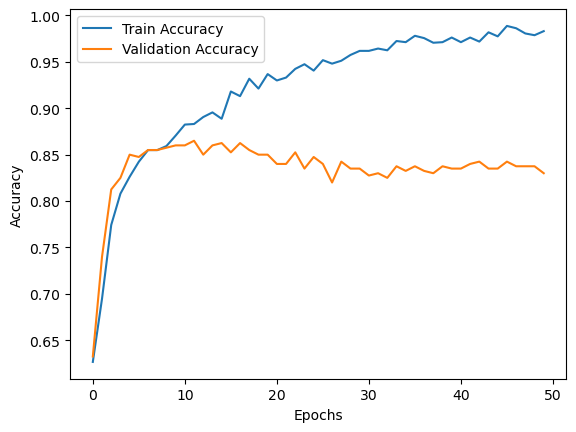

Model accuracy for prediction run after training: 85.5%


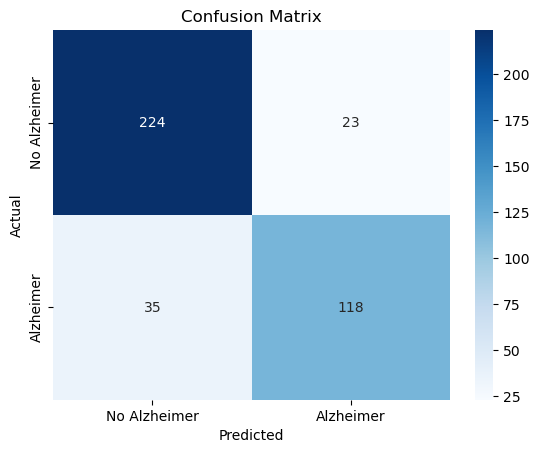

In [41]:
# Running the base model with all the features first to get the prediction accuracy

import os
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from keras import layers, Model
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix

# Ensure TensorFlow backend
os.environ["KERAS_BACKEND"] = "tensorflow"

# Loading dataset
file_url = "alzheimers_disease_data.csv"
dataframe = pd.read_csv(file_url)

# Splitting data into training and testing set
test_dataframe = dataframe.sample(frac=0.2, random_state=1337)
train_dataframe = dataframe.drop(test_dataframe.index)

# Convert dataframes to tf.data.Datasets
def dataframe_to_dataset(dataframe, target="Diagnosis"):
    dataframe = dataframe.copy()
    labels = dataframe.pop(target)
    dataframe.pop('PatientID')
    dataframe.pop('DoctorInCharge')
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    ds = ds.shuffle(buffer_size=len(dataframe)).batch(32)
    return ds

# Creating dataset objects for the dataframes
train_ds = dataframe_to_dataset(train_dataframe)
test_ds = dataframe_to_dataset(test_dataframe)

# Preprocessing layers for numerical and categorical features
def encode_feature(feature, name, dataset, is_string=False):
    lookup_class = layers.StringLookup if is_string else layers.IntegerLookup
    lookup = lookup_class(output_mode="binary")
    feature_ds = dataset.map(lambda x, y: x[name]).map(lambda x: tf.expand_dims(x, -1))
    lookup.adapt(feature_ds)
    return lookup(feature)

def normalize_feature(feature, name, dataset):
    normalizer = layers.Normalization()
    feature_ds = dataset.map(lambda x, y: tf.expand_dims(x[name], -1))
    normalizer.adapt(feature_ds)
    return normalizer(feature)

# Defining and encoding the features
inputs = {
    'Age': layers.Input(name='Age', shape=(1,), dtype='int64'),
    'Gender': layers.Input(name='Gender', shape=(1,), dtype='int64'),
    'Ethnicity': layers.Input(name='Ethnicity', shape=(1,), dtype='int64'),
    'EducationLevel': layers.Input(name='EducationLevel', shape=(1,), dtype='int64'),
    'BMI': layers.Input(name='BMI', shape=(1,), dtype='float32'),
    'Smoking': layers.Input(name='Smoking', shape=(1,), dtype='int64'),
    'AlcoholConsumption': layers.Input(name='AlcoholConsumption', shape=(1,), dtype='float32'),
    'PhysicalActivity': layers.Input(name='PhysicalActivity', shape=(1,), dtype='float32'),
    'DietQuality': layers.Input(name='DietQuality', shape=(1,), dtype='float32'),
    'SleepQuality': layers.Input(name='SleepQuality', shape=(1,), dtype='float32'),
    'FamilyHistoryAlzheimers': layers.Input(name='FamilyHistoryAlzheimers', shape=(1,), dtype='int64'),
    'CardiovascularDisease': layers.Input(name='CardiovascularDisease', shape=(1,), dtype='int64'),
    'Diabetes': layers.Input(name='Diabetes', shape=(1,), dtype='int64'),
    'Depression': layers.Input(name='Depression', shape=(1,), dtype='int64'),
    'HeadInjury': layers.Input(name='HeadInjury', shape=(1,), dtype='int64'),
    'Hypertension': layers.Input(name='Hypertension', shape=(1,), dtype='int64'),
    'SystolicBP': layers.Input(name='SystolicBP', shape=(1,), dtype='int64'),
    'DiastolicBP': layers.Input(name='DiastolicBP', shape=(1,), dtype='int64'),
    'CholesterolTotal': layers.Input(name='CholesterolTotal', shape=(1,), dtype='float32'),
    'CholesterolLDL': layers.Input(name='CholesterolLDL', shape=(1,), dtype='float32'),
    'CholesterolHDL': layers.Input(name='CholesterolHDL', shape=(1,), dtype='float32'),
    'CholesterolTriglycerides': layers.Input(name='CholesterolTriglycerides', shape=(1,), dtype='float32'),
    'MMSE': layers.Input(name='MMSE', shape=(1,), dtype='float32'),
    'FunctionalAssessment': layers.Input(name='FunctionalAssessment', shape=(1,), dtype='float32'),
    'MemoryComplaints': layers.Input(name='MemoryComplaints', shape=(1,), dtype='int64'),
    'BehavioralProblems': layers.Input(name='BehavioralProblems', shape=(1,), dtype='int64'),
    'ADL': layers.Input(name='ADL', shape=(1,), dtype='float32'),
    'Confusion': layers.Input(name='Confusion', shape=(1,), dtype='int64'),
    'Disorientation': layers.Input(name='Disorientation', shape=(1,), dtype='int64'),
    'PersonalityChanges': layers.Input(name='PersonalityChanges', shape=(1,), dtype='int64'),
    'DifficultyCompletingTasks': layers.Input(name='DifficultyCompletingTasks', shape=(1,), dtype='int64'),
    'Forgetfulness': layers.Input(name='Forgetfulness', shape=(1,), dtype='int64'),
    }

encoded_features = [
    encode_feature(inputs['Age'], 'Age', train_ds),
    encode_feature(inputs['Gender'], 'Gender', train_ds),
    encode_feature(inputs['Ethnicity'], 'Ethnicity', train_ds),
    encode_feature(inputs['EducationLevel'], 'EducationLevel', train_ds),
    encode_feature(inputs['Smoking'], 'Smoking', train_ds),
    encode_feature(inputs['FamilyHistoryAlzheimers'], 'FamilyHistoryAlzheimers', train_ds),
    encode_feature(inputs['CardiovascularDisease'], 'CardiovascularDisease', train_ds),
    encode_feature(inputs['Diabetes'], 'Diabetes', train_ds),
    encode_feature(inputs['Depression'], 'Depression', train_ds),
    encode_feature(inputs['HeadInjury'], 'HeadInjury', train_ds),
    encode_feature(inputs['Hypertension'], 'Hypertension', train_ds),
    encode_feature(inputs['SystolicBP'], 'SystolicBP', train_ds),
    encode_feature(inputs['DiastolicBP'], 'DiastolicBP', train_ds),
    encode_feature(inputs['MemoryComplaints'], 'MemoryComplaints', train_ds),
    encode_feature(inputs['BehavioralProblems'], 'BehavioralProblems', train_ds),
    encode_feature(inputs['Confusion'], 'Confusion', train_ds),
    encode_feature(inputs['Disorientation'], 'Disorientation', train_ds),
    encode_feature(inputs['PersonalityChanges'], 'PersonalityChanges', train_ds),
    encode_feature(inputs['DifficultyCompletingTasks'], 'DifficultyCompletingTasks', train_ds),
    encode_feature(inputs['Forgetfulness'], 'Forgetfulness', train_ds),
    normalize_feature(inputs['BMI'], 'BMI', train_ds),
    normalize_feature(inputs['AlcoholConsumption'], 'AlcoholConsumption', train_ds),
    normalize_feature(inputs['PhysicalActivity'], 'PhysicalActivity', train_ds),
    normalize_feature(inputs['DietQuality'], 'DietQuality', train_ds),
    normalize_feature(inputs['SleepQuality'], 'SleepQuality', train_ds),
    normalize_feature(inputs['CholesterolTotal'], 'CholesterolTotal', train_ds),
    normalize_feature(inputs['CholesterolLDL'], 'CholesterolLDL', train_ds),
    normalize_feature(inputs['CholesterolHDL'], 'CholesterolHDL', train_ds),
    normalize_feature(inputs['CholesterolTriglycerides'], 'CholesterolTriglycerides', train_ds),
    normalize_feature(inputs['MMSE'], 'MMSE', train_ds),
    normalize_feature(inputs['FunctionalAssessment'], 'FunctionalAssessment', train_ds),
    normalize_feature(inputs['ADL'], 'ADL', train_ds)
    ]

# Building the model
def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(32, activation='relu')(all_features)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=50, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=50, validation_data=test_ds, callbacks=early_stopping, verbose=0)

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()




Train Accuracy: 85.37836170196533%
Test Accuracy: 86.52500033378601%


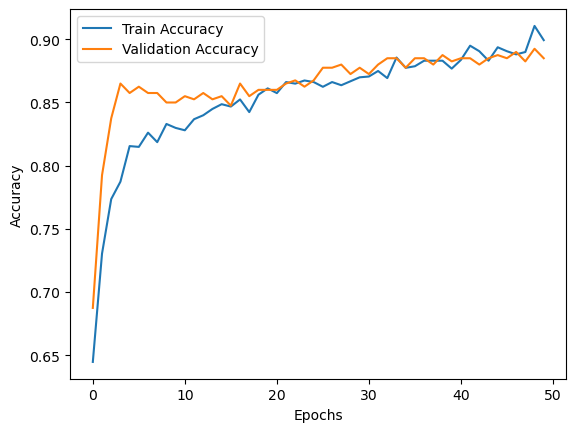

Model accuracy for prediction run after training: 88.5%


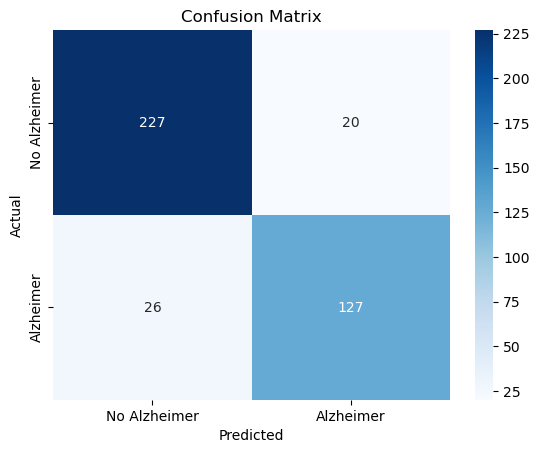

In [42]:
# Only keeping features that are directly or indirectly proportionate to the diagnosis by 0.03 or more

import os
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from keras import layers, Model
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix

# Ensure TensorFlow backend
os.environ["KERAS_BACKEND"] = "tensorflow"

# Loading dataset
file_url = "alzheimers_disease_data.csv"
data = pd.read_csv(file_url)
dataframe = data[["EducationLevel","BMI","SleepQuality","FamilyHistoryAlzheimers","CardiovascularDisease","Diabetes","Hypertension","CholesterolLDL","CholesterolHDL","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Splitting data into training and testing set
test_dataframe = dataframe.sample(frac=0.2, random_state=1337)
train_dataframe = dataframe.drop(test_dataframe.index)

# Convert dataframes to tf.data.Datasets
def dataframe_to_dataset(dataframe, target="Diagnosis"):
    dataframe = dataframe.copy()
    labels = dataframe.pop(target)
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    ds = ds.shuffle(buffer_size=len(dataframe)).batch(32)
    return ds

# Creating dataset objects for the dataframes
train_ds = dataframe_to_dataset(train_dataframe)
test_ds = dataframe_to_dataset(test_dataframe)

# Preprocessing layers for numerical and categorical features
def encode_feature(feature, name, dataset, is_string=False):
    lookup_class = layers.StringLookup if is_string else layers.IntegerLookup
    lookup = lookup_class(output_mode="binary")
    feature_ds = dataset.map(lambda x, y: x[name]).map(lambda x: tf.expand_dims(x, -1))
    lookup.adapt(feature_ds)
    return lookup(feature)

def normalize_feature(feature, name, dataset):
    normalizer = layers.Normalization()
    feature_ds = dataset.map(lambda x, y: tf.expand_dims(x[name], -1))
    normalizer.adapt(feature_ds)
    return normalizer(feature)

# Defining and encoding the features
inputs = {
    'EducationLevel': layers.Input(name='EducationLevel', shape=(1,), dtype='int64'),
    'BMI': layers.Input(name='BMI', shape=(1,), dtype='float32'),
    'SleepQuality': layers.Input(name='SleepQuality', shape=(1,), dtype='float32'),
    'FamilyHistoryAlzheimers': layers.Input(name='FamilyHistoryAlzheimers', shape=(1,), dtype='int64'),
    'CardiovascularDisease': layers.Input(name='CardiovascularDisease', shape=(1,), dtype='int64'),
    'Diabetes': layers.Input(name='Diabetes', shape=(1,), dtype='int64'),
    'Hypertension': layers.Input(name='Hypertension', shape=(1,), dtype='int64'),
    'CholesterolLDL': layers.Input(name='CholesterolLDL', shape=(1,), dtype='float32'),
    'CholesterolHDL': layers.Input(name='CholesterolHDL', shape=(1,), dtype='float32'),
    'MMSE': layers.Input(name='MMSE', shape=(1,), dtype='float32'),
    'FunctionalAssessment': layers.Input(name='FunctionalAssessment', shape=(1,), dtype='float32'),
    'MemoryComplaints': layers.Input(name='MemoryComplaints', shape=(1,), dtype='int64'),
    'BehavioralProblems': layers.Input(name='BehavioralProblems', shape=(1,), dtype='int64'),
    'ADL': layers.Input(name='ADL', shape=(1,), dtype='float32'),
    }

encoded_features = [
    encode_feature(inputs['EducationLevel'], 'EducationLevel', train_ds),
    encode_feature(inputs['FamilyHistoryAlzheimers'], 'FamilyHistoryAlzheimers', train_ds),
    encode_feature(inputs['CardiovascularDisease'], 'CardiovascularDisease', train_ds),
    encode_feature(inputs['Diabetes'], 'Diabetes', train_ds),
    encode_feature(inputs['Hypertension'], 'Hypertension', train_ds),
    encode_feature(inputs['MemoryComplaints'], 'MemoryComplaints', train_ds),
    encode_feature(inputs['BehavioralProblems'], 'BehavioralProblems', train_ds),
    normalize_feature(inputs['BMI'], 'BMI', train_ds),
    normalize_feature(inputs['SleepQuality'], 'SleepQuality', train_ds),
    normalize_feature(inputs['CholesterolLDL'], 'CholesterolLDL', train_ds),
    normalize_feature(inputs['CholesterolHDL'], 'CholesterolHDL', train_ds),
    normalize_feature(inputs['MMSE'], 'MMSE', train_ds),
    normalize_feature(inputs['FunctionalAssessment'], 'FunctionalAssessment', train_ds),
    normalize_feature(inputs['ADL'], 'ADL', train_ds)
    ]

# Building the model
def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(32, activation='relu')(all_features)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=50, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=50, validation_data=test_ds, callbacks=early_stopping, verbose=0)

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



Train Accuracy: 87.2432769536972%
Test Accuracy: 89.69000029563904%


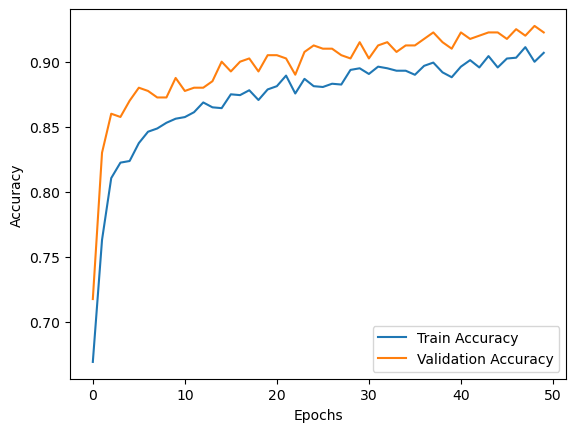

Model accuracy for prediction run after training: 92.75%


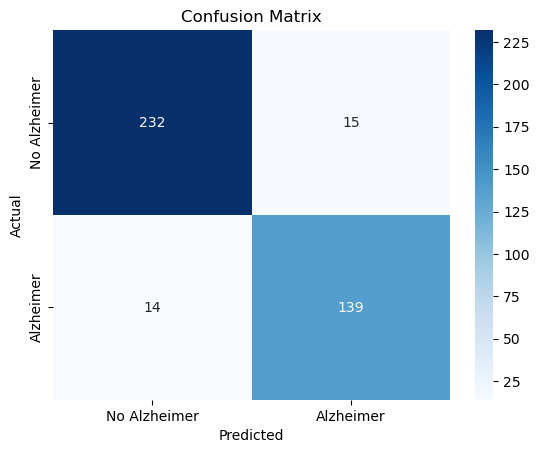

In [43]:
# Only keeping features that are directly or indirectly proportionate to the diagnosis by or 0.10 or more

import os
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from keras import layers, Model
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix

# Ensure TensorFlow backend
os.environ["KERAS_BACKEND"] = "tensorflow"

# Loading dataset
file_url = "alzheimers_disease_data.csv"
data = pd.read_csv(file_url)
dataframe = data[["SleepQuality","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Splitting data into training and testing set
test_dataframe = dataframe.sample(frac=0.2, random_state=1337)
train_dataframe = dataframe.drop(test_dataframe.index)

# Convert dataframes to tf.data.Datasets
def dataframe_to_dataset(dataframe, target="Diagnosis"):
    dataframe = dataframe.copy()
    labels = dataframe.pop(target)
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    ds = ds.shuffle(buffer_size=len(dataframe)).batch(32)
    return ds

# Creating dataset objects for the dataframes
train_ds = dataframe_to_dataset(train_dataframe)
test_ds = dataframe_to_dataset(test_dataframe)

# Preprocessing layers for numerical and categorical features
def encode_feature(feature, name, dataset, is_string=False):
    lookup_class = layers.StringLookup if is_string else layers.IntegerLookup
    lookup = lookup_class(output_mode="binary")
    feature_ds = dataset.map(lambda x, y: x[name]).map(lambda x: tf.expand_dims(x, -1))
    lookup.adapt(feature_ds)
    return lookup(feature)

def normalize_feature(feature, name, dataset):
    normalizer = layers.Normalization()
    feature_ds = dataset.map(lambda x, y: tf.expand_dims(x[name], -1))
    normalizer.adapt(feature_ds)
    return normalizer(feature)

# Defining and encoding the features
inputs = {
    'SleepQuality': layers.Input(name='SleepQuality', shape=(1,), dtype='float32'),
    'MMSE': layers.Input(name='MMSE', shape=(1,), dtype='float32'),
    'FunctionalAssessment': layers.Input(name='FunctionalAssessment', shape=(1,), dtype='float32'),
    'MemoryComplaints': layers.Input(name='MemoryComplaints', shape=(1,), dtype='int64'),
    'BehavioralProblems': layers.Input(name='BehavioralProblems', shape=(1,), dtype='int64'),
    'ADL': layers.Input(name='ADL', shape=(1,), dtype='float32'),
    }

encoded_features = [
    encode_feature(inputs['MemoryComplaints'], 'MemoryComplaints', train_ds),
    encode_feature(inputs['BehavioralProblems'], 'BehavioralProblems', train_ds),
    normalize_feature(inputs['SleepQuality'], 'SleepQuality', train_ds),
    normalize_feature(inputs['MMSE'], 'MMSE', train_ds),
    normalize_feature(inputs['FunctionalAssessment'], 'FunctionalAssessment', train_ds),
    normalize_feature(inputs['ADL'], 'ADL', train_ds)
    ]

# Building the model
def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(32, activation='relu')(all_features)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=50, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=50, validation_data=test_ds, callbacks=early_stopping, verbose=0)

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



## Conclusion:

This test had some interesting results. The first graph and accuracy ratings above it are generated by the model when training. The second rating and confusion matrix is generated by analyzing results of model prediction.

At first it might seem that the training accuracy is going down when removing features but the test accuracy seems to be improving. The prediction result accuracy also seems to have drastic improvement.

Removing unnecessary features have narrowed the gap between train and test accuracy ratings which is good for us as it means the prediction will be more reliable.

## Adding layers

Testing with 4 different models with different number of hidden layers



In [49]:
# Importing libraries and preprocessing data in this cell as we no longer need to make adjustments to data.
# All the tests from now on can use this preprocessed data

import os
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from keras import layers, Model
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix

# Ensure TensorFlow backend
os.environ["KERAS_BACKEND"] = "tensorflow"

# Loading dataset
data_url = "alzheimers_disease_data.csv"
data = pd.read_csv(data_url)
dataframe = data[["SleepQuality","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Splitting data into training and testing set
test_dataframe = dataframe.sample(frac=0.2, random_state=1337)
train_dataframe = dataframe.drop(test_dataframe.index)

# Convert dataframes to tf.data.Datasets
def dataframe_to_dataset(dataframe, target="Diagnosis"):
    dataframe = dataframe.copy()
    labels = dataframe.pop(target)
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    ds = ds.shuffle(buffer_size=len(dataframe)).batch(32)
    return ds

# Creating dataset objects for the dataframes
train_ds = dataframe_to_dataset(train_dataframe)
test_ds = dataframe_to_dataset(test_dataframe)

# Preprocessing layers for numerical and categorical features
def encode_feature(feature, name, dataset, is_string=False):
    lookup_class = layers.StringLookup if is_string else layers.IntegerLookup
    lookup = lookup_class(output_mode="binary")
    feature_ds = dataset.map(lambda x, y: x[name]).map(lambda x: tf.expand_dims(x, -1))
    lookup.adapt(feature_ds)
    return lookup(feature)

def normalize_feature(feature, name, dataset):
    normalizer = layers.Normalization()
    feature_ds = dataset.map(lambda x, y: tf.expand_dims(x[name], -1))
    normalizer.adapt(feature_ds)
    return normalizer(feature)

# Defining and encoding the features
inputs = {
    'SleepQuality': layers.Input(name='SleepQuality', shape=(1,), dtype='float32'),
    'MMSE': layers.Input(name='MMSE', shape=(1,), dtype='float32'),
    'FunctionalAssessment': layers.Input(name='FunctionalAssessment', shape=(1,), dtype='float32'),
    'MemoryComplaints': layers.Input(name='MemoryComplaints', shape=(1,), dtype='int64'),
    'BehavioralProblems': layers.Input(name='BehavioralProblems', shape=(1,), dtype='int64'),
    'ADL': layers.Input(name='ADL', shape=(1,), dtype='float32'),
    }

encoded_features = [
    encode_feature(inputs['MemoryComplaints'], 'MemoryComplaints', train_ds),
    encode_feature(inputs['BehavioralProblems'], 'BehavioralProblems', train_ds),
    normalize_feature(inputs['SleepQuality'], 'SleepQuality', train_ds),
    normalize_feature(inputs['MMSE'], 'MMSE', train_ds),
    normalize_feature(inputs['FunctionalAssessment'], 'FunctionalAssessment', train_ds),
    normalize_feature(inputs['ADL'], 'ADL', train_ds)
    ]



Building four models with different number of layers and running them in a loop for comparison

Also dding a dropout layer after each layer to keep the output stable

Setting early stopping patience to 20 and epoch to 100 to prevent overfitting on this size dataset.

This is the basic model with no changes (2 hidden layers)

Train Accuracy: 88.83071559667587%
Test Accuracy: 89.30697673559189%


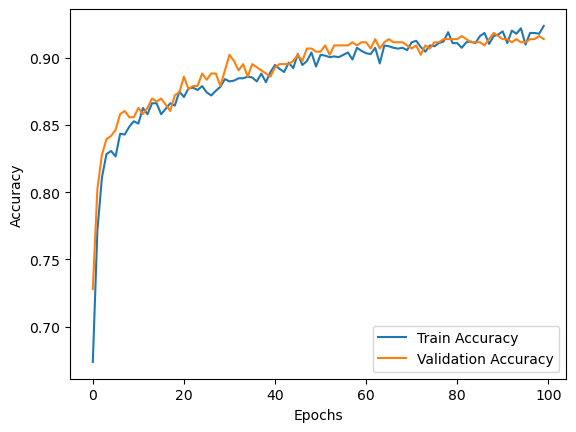

Model accuracy for prediction run after training: 91.16279069767442%


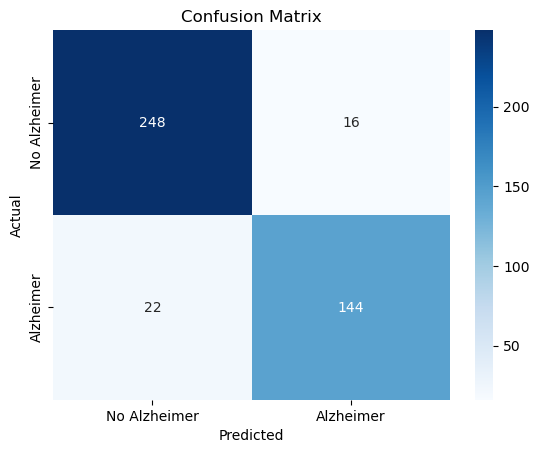

In [36]:
# Model 1 with no change (2 layers)

def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(32, activation='relu')(all_features)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This is the basic model with no changes (2 hidden layers)\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



This model has 4 hidden layers

Train Accuracy: 91.84741919690912%
Test Accuracy: 91.72455467186965%


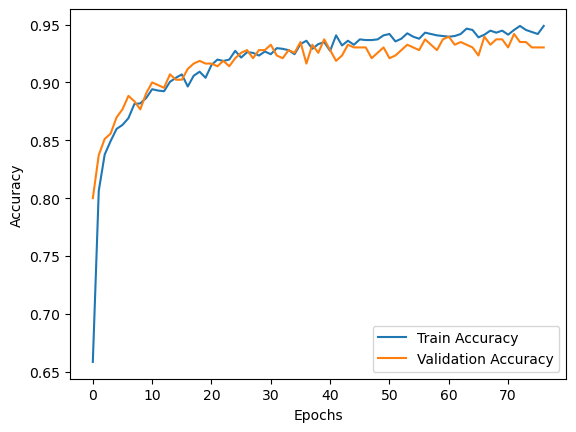

Model accuracy for prediction run after training: 93.72093023255815%


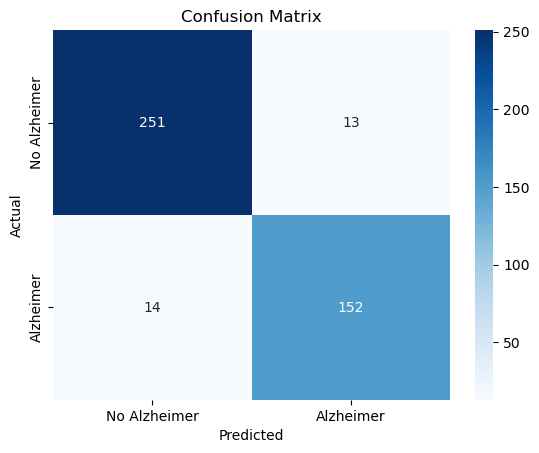

In [37]:
# Model with 4 layers:

def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(128, activation='relu')(all_features)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model has 4 hidden layers\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()








This model has 8 hidden layers

Train Accuracy: 91.5460425264695%
Test Accuracy: 91.39534848577836%


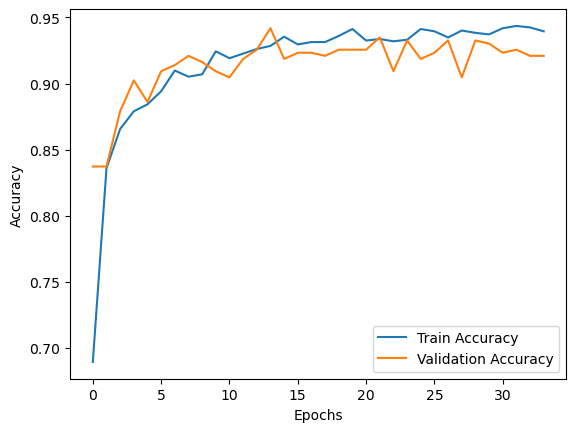

Model accuracy for prediction run after training: 94.18604651162791%


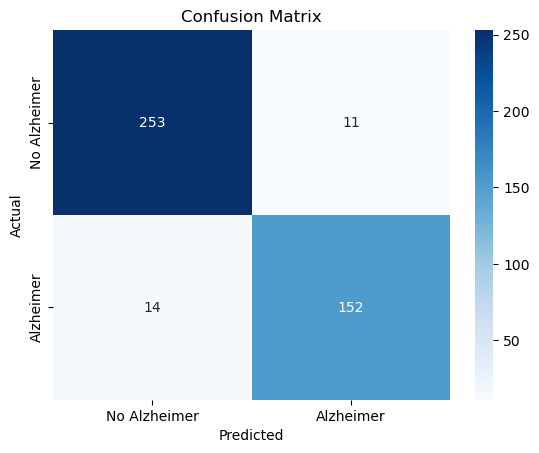

In [39]:
# This model has 8 hidden layers

def build_model_4():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(2048, activation='relu')(all_features)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(1024,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(512,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='relu')(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model has 8 hidden layers\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



#### Overfitting

It seems that the model is facing major overfitting issues after 4 layers as it is unable to go past the 50 epoch limit by EarlyStopping callback. The first two are able to do 100 epochs without overfitting.

To resolve this issue, let's add a batch normalization layer to stabilize the learning process and help reduce overfitting.



This is the basic model with no changes (2 hidden layers)

Train Accuracy: 89.60350203514099%
Test Accuracy: 91.83000087738037%


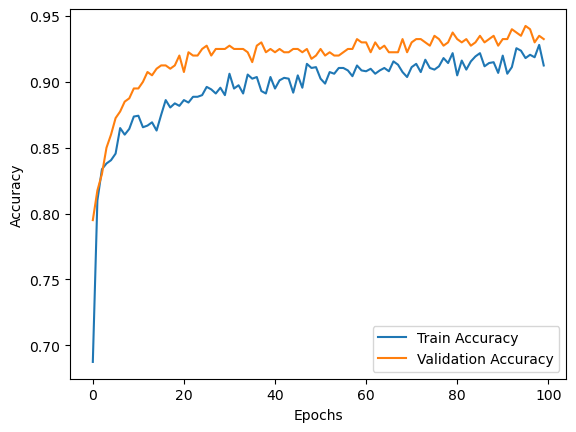

Model accuracy for prediction run after training: 93.5%


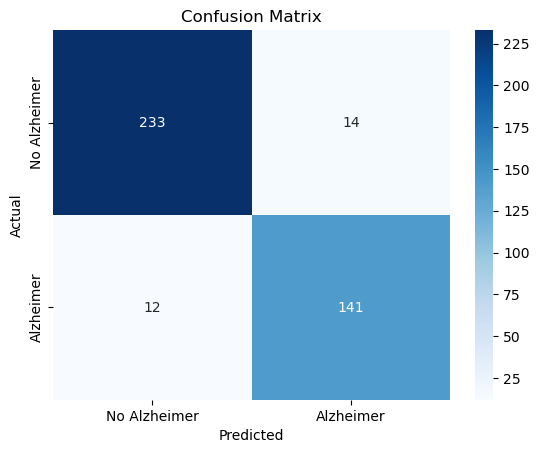

In [45]:
# Model 1 with no change (2 layers)

def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(32, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This is the basic model with no changes (2 hidden layers)\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



This model has 4 hidden layers

Train Accuracy: 88.73671090602875%
Test Accuracy: 91.82500052452087%


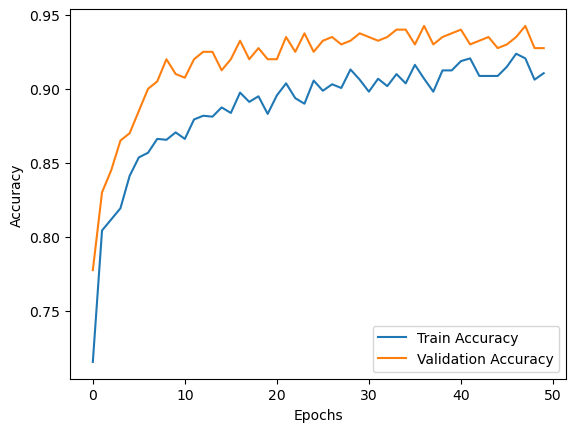

Model accuracy for prediction run after training: 93.75%


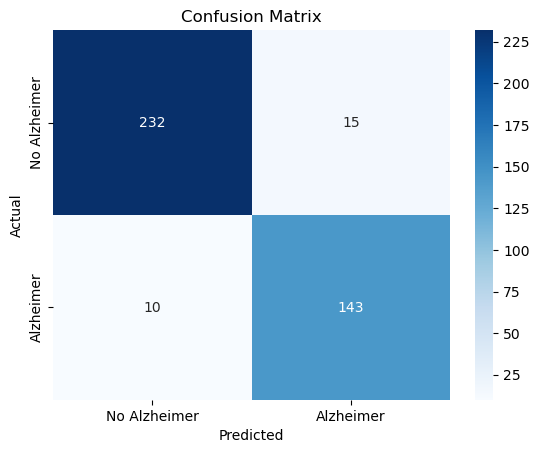

In [46]:
# Model with 4 layers:

def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(128, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model has 4 hidden layers\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()








This model has 6 hidden layers

Train Accuracy: 89.67081698504361%
Test Accuracy: 90.74545491825451%


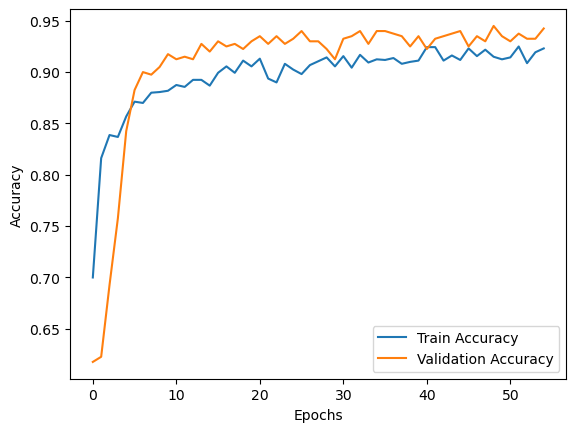

Model accuracy for prediction run after training: 94.0%


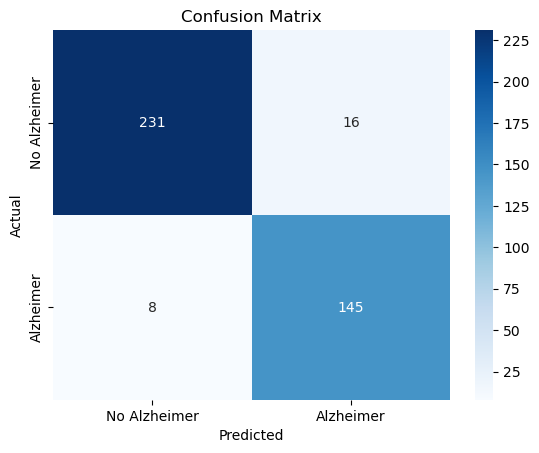

In [47]:
# Model with 6 layers


def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(512, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model has 6 hidden layers\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()







This model has 8 hidden layers

Train Accuracy: 89.17931684038855%
Test Accuracy: 89.33522768995978%


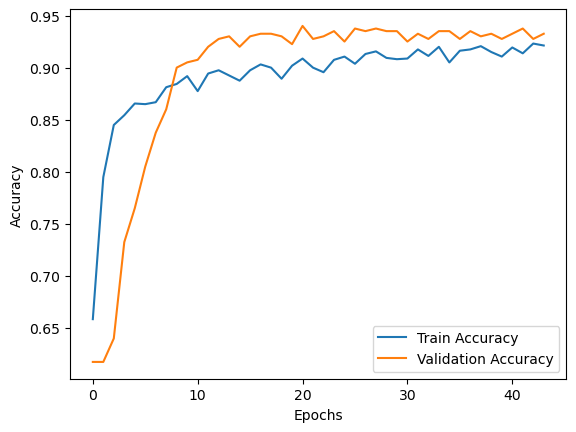

Model accuracy for prediction run after training: 93.5%


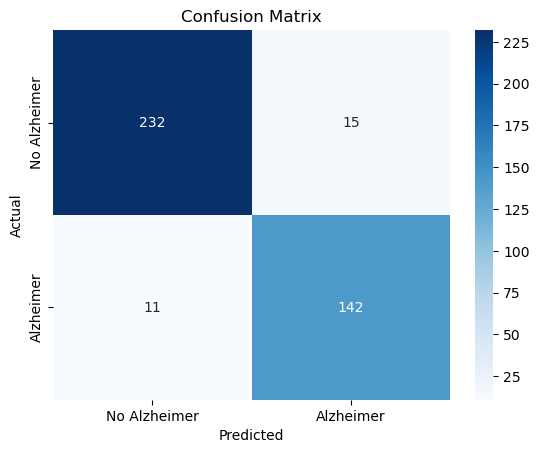

In [48]:
# This model has 8 hidden layers

def build_model_4():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(2048, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(1024,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(512,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model has 8 hidden layers\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



#### Conclusion:

It seems that the dataset is of moderate size but not large enough for too many layers as we keep running into overfitting issues.

The batch normalization layer made an improvement but it seems that it starts to overfit very quickly on 8 layers and seems to be performing better on 6 layers.

#### Layer activation function

Trying different activation functions for a 6 layered model.

The first model will be same as last but the last hidden layer will be tanh for the rest of the models as it is best for classifying binary outputs before the output layer.

The second model will have a leaky_relu layers to prevent dying neuron problem. Starting with a relu layer as to get the right classification to feed into leaky_relu

The third model will be swish which is an activation function introduced by google and it outperforms relu without the dying neuron problem.

The fourth model will be start with a relu then it will be a mix of swish and leaky relu

This model is the basic one with tanh as the last hidden layer

Train Accuracy: 90.23036670684814%
Test Accuracy: 90.11627912521362%


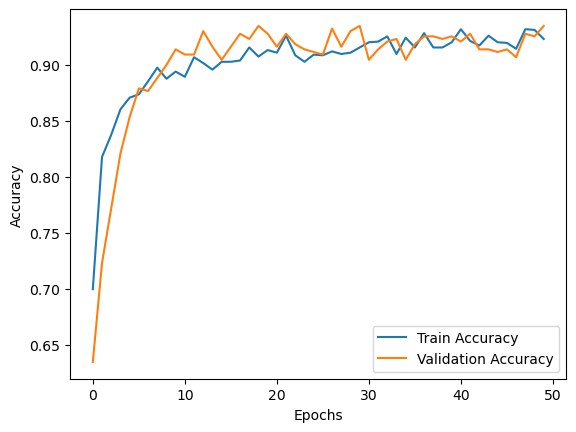

Model accuracy for prediction run after training: 93.48837209302326%


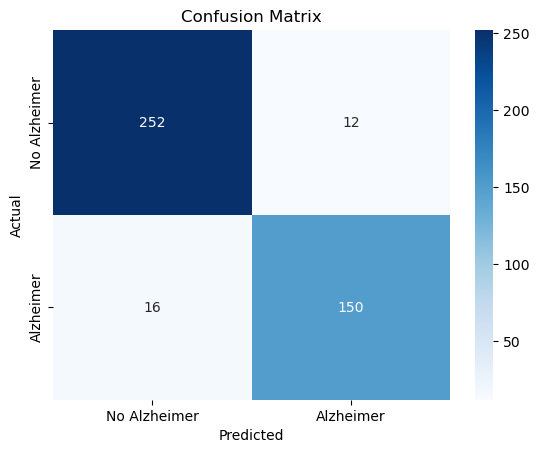

In [66]:
# First model with last hidden layer as tanh


def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(512, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='tanh')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model is the basic one with tanh as the last hidden layer\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



This model has a starting relu then leaky_relu layers

Train Accuracy: 90.30891549892914%
Test Accuracy: 89.92844407375043%


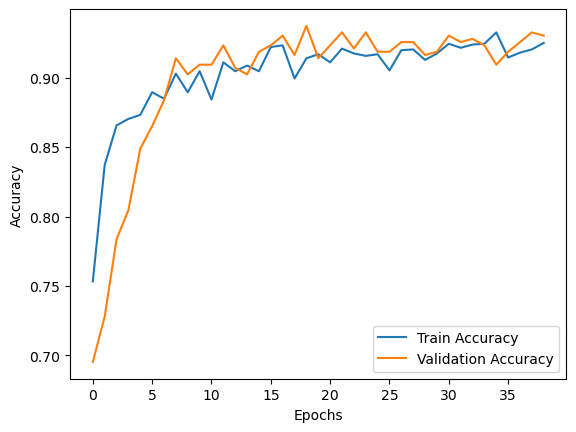

Model accuracy for prediction run after training: 93.72093023255815%


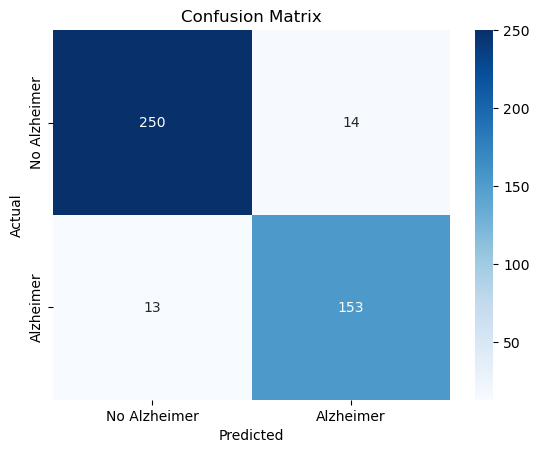

In [80]:
# This model has relu first layer for better classification and then leaky_relu layers to prevent dying neuron issue


def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(512, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='leaky_relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='leaky_relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='leaky_relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='leaky_relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='tanh')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model has a starting relu then leaky_relu layers\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()







This model has swish layers

Train Accuracy: 88.4110366659505%
Test Accuracy: 89.82142837984222%


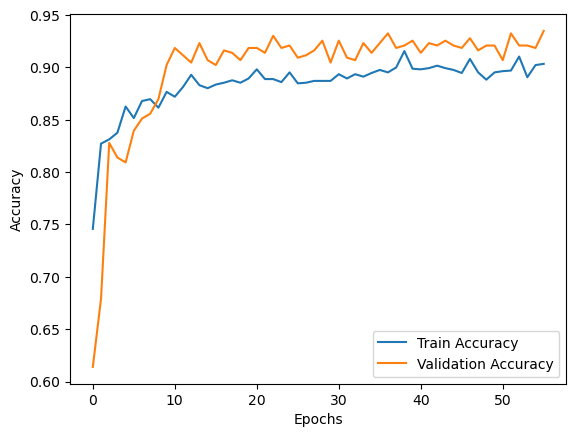

Model accuracy for prediction run after training: 92.32558139534883%


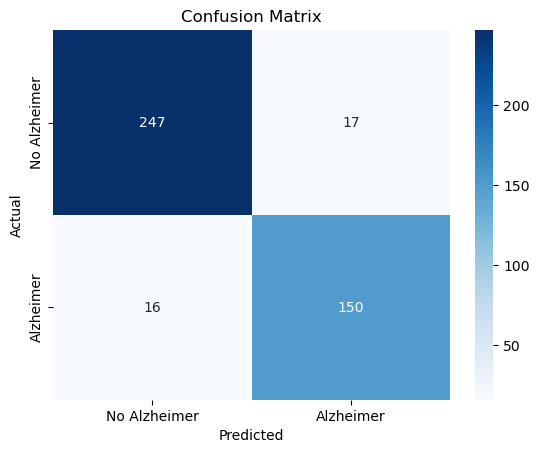

In [72]:
# This model has swish layers


def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(512, activation='swish')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='swish')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='swish')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='swish')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='swish')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='tanh')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model has swish layers\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



This model is a mix of relu, leaky_relu, and swish

Train Accuracy: 90.70121256204752%
Test Accuracy: 90.48300523024338%


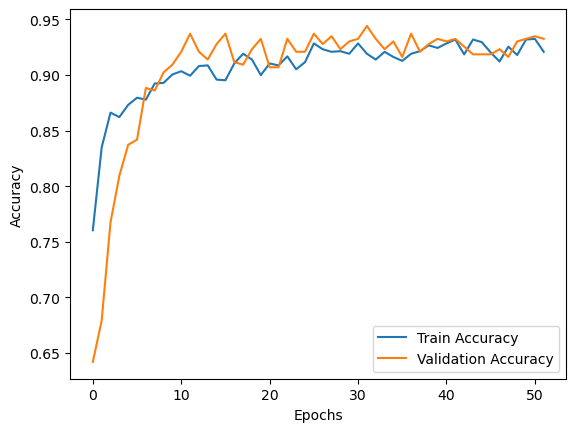

Model accuracy for prediction run after training: 94.41860465116278%


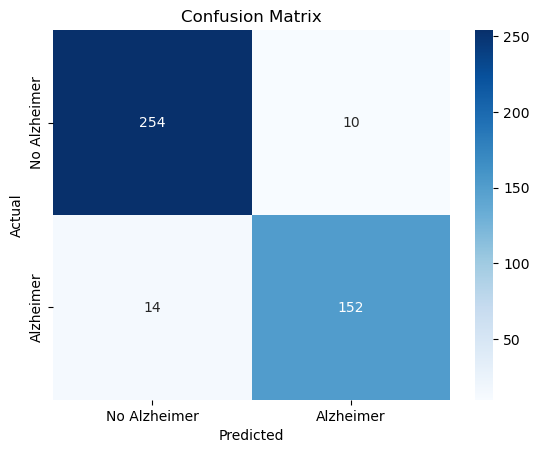

In [67]:
# This model is a mix of relu, leaky_relu, and swish


def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(512, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='swish')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='leaky_relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='tanh')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

print("This model is a mix of relu, leaky_relu, and swish\n")

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()







## Final conclusion for Neural Network model

Leaky_relu started to overfit very quickly and did not perform well on all layers.

Swish is a great activation function but it seems that for a simpler task with smaller dataset like this one, it was not good to have it on all layers.

Starting with the relu layer gave the model the stability it needed for a 0 and 1 classification task.

Having one leaky_rely at the end as a backup for relu in case the dataset was too big is a good idea. Having two relu on top feeding into two swish produced the best results by far.

I tried multiple other combinations on the last test by quickly switching the activation function and running the code cell. The above configuration was the best so far.




# Optimizing Random Forest Classifier

#### Reducing features

The basic model has all the features of the dataset for training. First, we will reduce the features and see if it improves the prediction accuracy.

The correlation heatmap in the data analysis section is used for this.




Accuracy: 92.56%


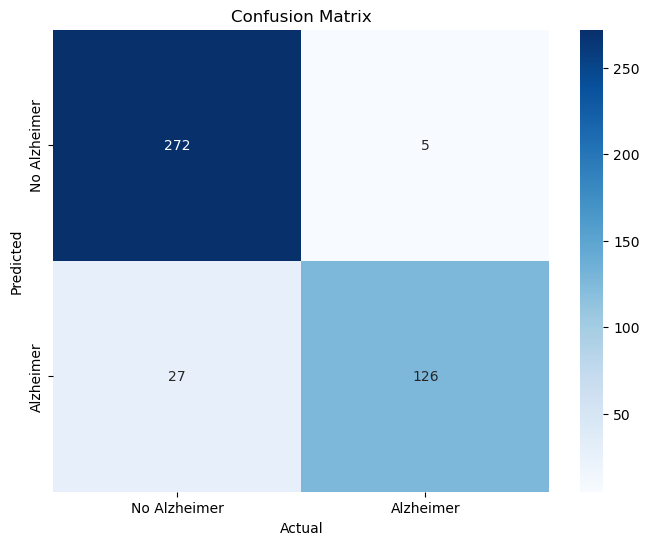

In [81]:
# Base model with all features for comparison

# Importing all the libraries and setting up training and testing dataframes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Loading dataset
file_url = "alzheimers_disease_data.csv"
dataframe = pd.read_csv(file_url)

# Removing sequential and unreadible data
dataframe.pop('PatientID')
dataframe.pop('DoctorInCharge')

# Separating features and target and converting to a numpy object
x = dataframe.iloc[:, :-1].values
y = dataframe.iloc[:, -1].values



# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Preprocessing - Applying StandardScaler() to datasets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Building the model
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

# Model accuracy for prediction
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Plotting confusion matrix to show actual and predicted values for both classes
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()




Accuracy: 94.19%


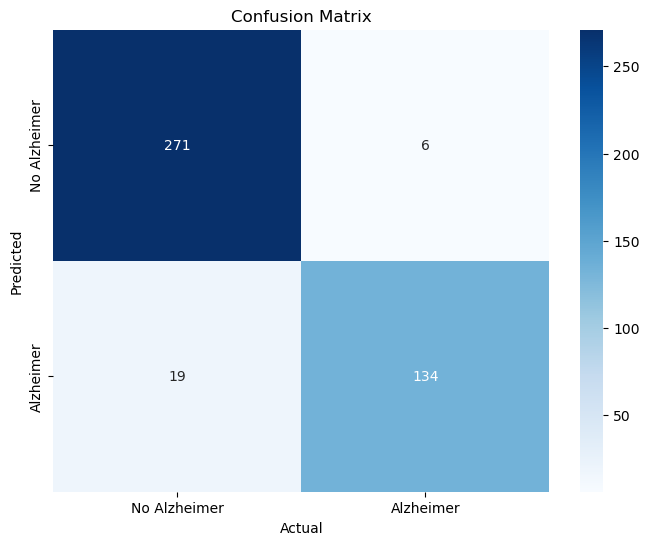

In [82]:
# Only keeping features that are directly or indirectly proportionate to the diagnosis by 0.03 or more

# Importing all the libraries and setting up training and testing dataframes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Loading dataset
file_url = "alzheimers_disease_data.csv"
data = pd.read_csv(file_url)
dataframe = data[["EducationLevel","BMI","SleepQuality","FamilyHistoryAlzheimers","CardiovascularDisease","Diabetes","Hypertension","CholesterolLDL","CholesterolHDL","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Separating features and target and converting to a numpy object
x = dataframe.iloc[:, :-1].values
y = dataframe.iloc[:, -1].values


# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Preprocessing - Applying StandardScaler() to datasets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Building the model
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

# Model accuracy for prediction
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Plotting confusion matrix to show actual and predicted values for both classes
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()




Accuracy: 95.12%


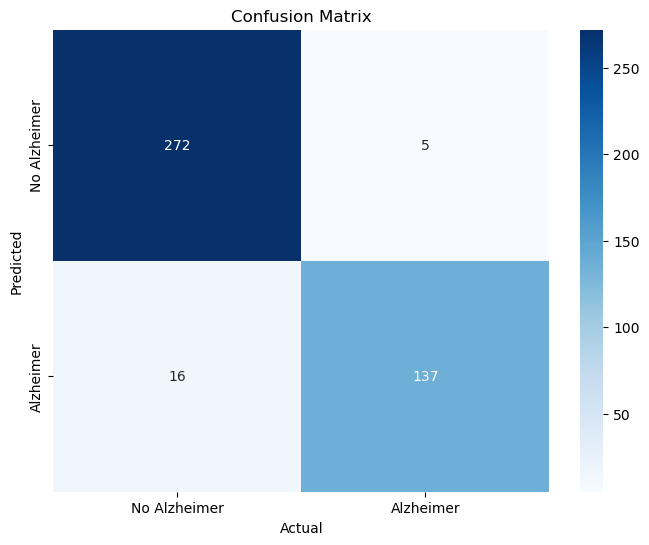

In [95]:
# Only keeping features that are directly or indirectly proportionate to the diagnosis by 0.10 or more


# Importing all the libraries and setting up training and testing dataframes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Loading dataset
file_url = "alzheimers_disease_data.csv"
data = pd.read_csv(file_url)
dataframe = data[["SleepQuality","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Separating features and target and converting to a numpy object
x = dataframe.iloc[:, :-1].values
y = dataframe.iloc[:, -1].values

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Preprocessing - Applying StandardScaler() to datasets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Building the model
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

# Model accuracy for prediction
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Plotting confusion matrix to show actual and predicted values for both classes
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()




## Conclusion

It seems that reducing the dataset made a huge impact.

Let's try to test with differen n_estimators value and see if we can improve the results.

----------------------------------------------------------------------------------------------------

This run has 50 n_estimators

Accuracy: 94.19%


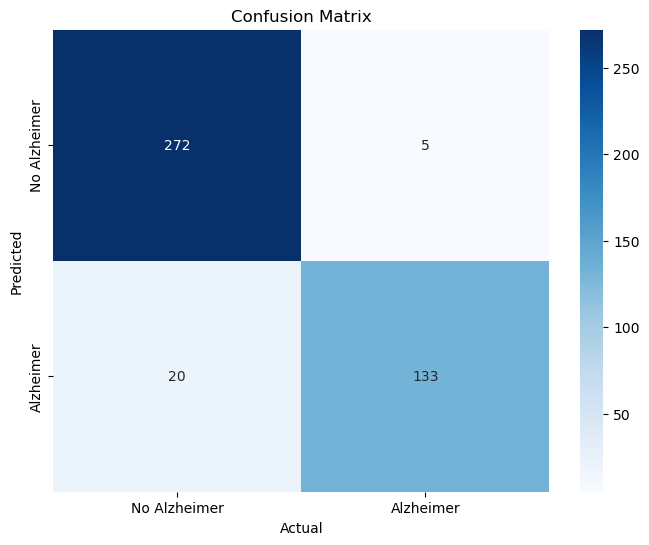

----------------------------------------------------------------------------------------------------

This run has 100 n_estimators

Accuracy: 95.12%


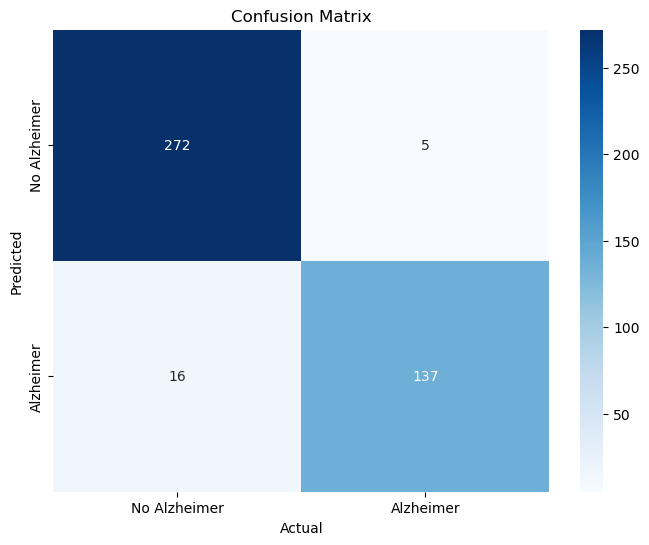

----------------------------------------------------------------------------------------------------

This run has 200 n_estimators

Accuracy: 95.12%


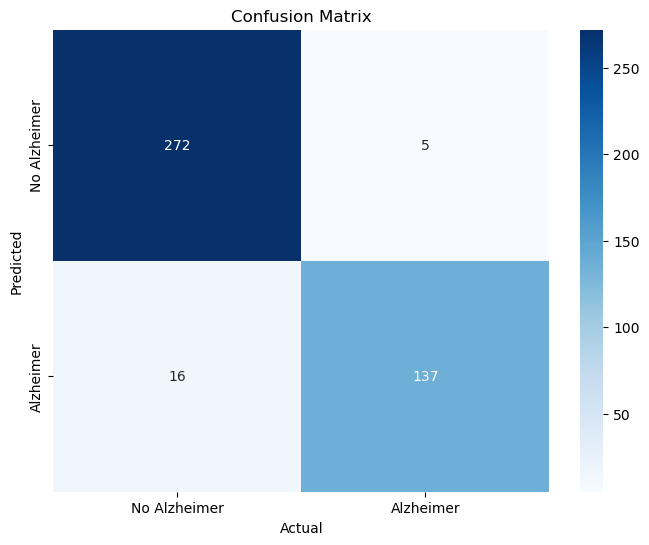

In [97]:
# Testing with 3 different n_estimators values


# Importing all the libraries and setting up training and testing dataframes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Loading dataset
file_url = "alzheimers_disease_data.csv"
data = pd.read_csv(file_url)
dataframe = data[["SleepQuality","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Separating features and target and converting to a numpy object
x = dataframe.iloc[:, :-1].values
y = dataframe.iloc[:, -1].values

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Preprocessing - Applying StandardScaler() to datasets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

n_est = [50,100,200]

for n in n_est:
    print('-'*100)
    print(f"\nThis run has {n} n_estimators\n")

    # Building the model
    classifier = RandomForestClassifier(n_estimators=n, random_state=42)
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)


    # Model accuracy for prediction
    accuracy = accuracy_score(y_test, y_pred)
    print(f'Accuracy: {accuracy * 100:.2f}%')

    # Plotting confusion matrix to show actual and predicted values for both classes
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
    plt.title('Confusion Matrix')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.show()




## Conclusion

Reducing n_estimators made the accuracy worst while improving it did not make any meaningful impact. The current setting is optimal.

Let's try to use n_jobs = -1 for a run and do another without it to see if it makes a difference.

Adding the parameter will use all available cores.

----------------------------------------------------------------------------------------------------

This run is the basic run with default n_jobs

Accuracy: 95.12%


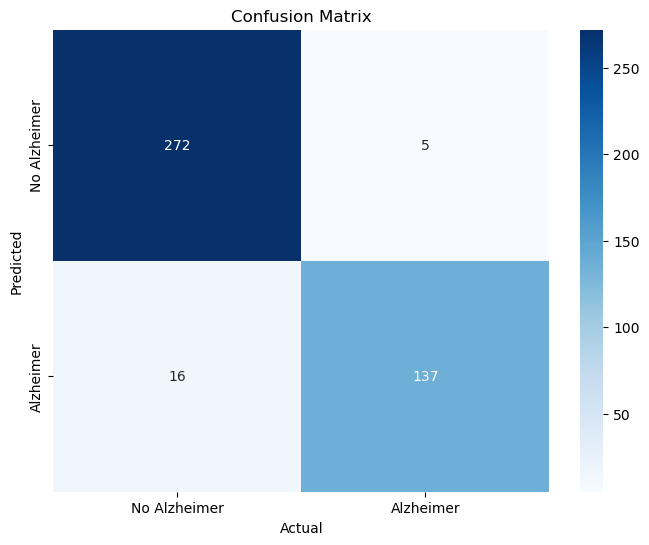

----------------------------------------------------------------------------------------------------

This run has has n_jobs = -1 to engage all cores

Accuracy: 95.12%


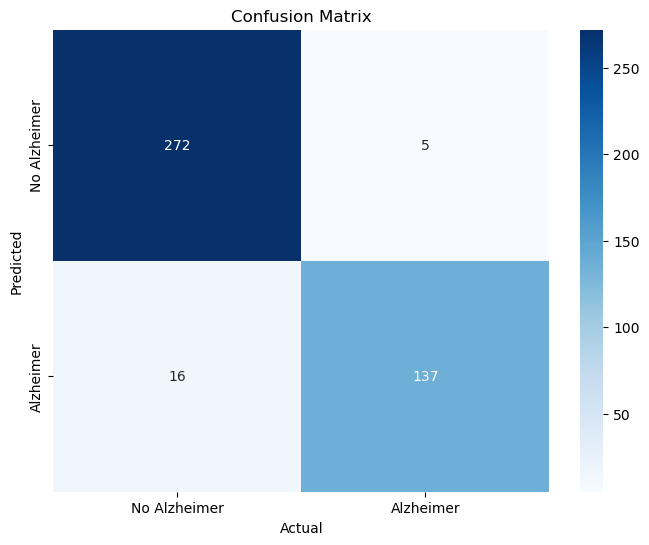

In [ ]:
# Testing with and without n_jobs = -1


# Importing all the libraries and setting up training and testing dataframes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Loading dataset
file_url = "alzheimers_disease_data.csv"
data = pd.read_csv(file_url)
dataframe = data[["SleepQuality","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Separating features and target and converting to a numpy object
x = dataframe.iloc[:, :-1].values
y = dataframe.iloc[:, -1].values

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Preprocessing - Applying StandardScaler() to datasets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



print('-'*100)
print(f"\nThis run is the basic run with default n_jobs\n")

# Building the model
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)


# Model accuracy for prediction
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Plotting confusion matrix to show actual and predicted values for both classes
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

print('-'*100)
print(f"\nThis run has has n_jobs = -1 to engage all cores\n")

# Building the model
classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)


# Model accuracy for prediction
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Plotting confusion matrix to show actual and predicted values for both classes
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()


## Final conclusion

Changing n_jobs or n_estimators did not make a difference as the RandomForestClassifier() works well with default parameters.

This dataset is not too big or small to change these parameters and the machine it is run on is powerful enough.

For older processors, it might be a good idea to use n_jobs = -1.